In [44]:
from pathlib import Path 
import rasterio
import re
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

In [45]:
data_dir = Path("../data/raw/")

lidar_dir = data_dir / "lidar"
mask_dir = data_dir / "masks"

print("Lidar folder exists:", lidar_dir.exists())
print("Mask folder exists:", mask_dir.exists())



Lidar folder exists: True
Mask folder exists: True


## Loads and Identifies Dataset

In [46]:
lidar_files = list(lidar_dir.glob("*.tif"))
mask_files = list(mask_dir.glob("*.tif"))
print("Number of Lidar files:", len(lidar_files))
print("Number of Mask files:", len(mask_files))

Number of Lidar files: 2094
Number of Mask files: 6282


In [47]:
print("First Lidar files")
for lidar_file in lidar_files[:5]:
    print(lidar_file.name)
print("\nFirst Mask files")
for mask_file in mask_files[:15]:
    print(mask_file.name)

First Lidar files
tile_1535_lidar.tif
tile_1465_lidar.tif
tile_418_lidar.tif
tile_1561_lidar.tif
tile_479_lidar.tif

First Mask files
tile_1117_mask_building.tif
tile_430_mask_building.tif
tile_1670_mask_aguada.tif
tile_1403_mask_building.tif
tile_1615_mask_aguada.tif
tile_88_mask_aguada.tif
tile_759_mask_platform.tif
tile_1232_mask_aguada.tif
tile_1811_mask_platform.tif
tile_396_mask_platform.tif
tile_241_mask_building.tif
tile_1627_mask_building.tif
tile_2009_mask_aguada.tif
tile_1330_mask_aguada.tif
tile_783_mask_aguada.tif


## File Name Parsing 

In [48]:
def get_lidar_data(path):
    match = re.fullmatch(r"tile_(\d+)_lidar\.tif", path.name)

    if match is None:
        return None
    return int(match.group(1))

print(lidar_files[0].name)
print(get_lidar_data(lidar_files[0]))

tile_1535_lidar.tif
1535


In [49]:
def get_mask_info(path):
    match = re.fullmatch(r"tile_(\d+)_mask_(building|platform|aguada)\.tif", path.name)

    if match is None:
        return None
    tile_id = int(match.group(1))
    class_name = match.group(2)
    return tile_id, class_name
print(mask_files[0].name)
print(get_mask_info(mask_files[0]))

tile_1117_mask_building.tif
(1117, 'building')


In [50]:
invalid_lidar = [path.name for path in lidar_files if get_lidar_data(path) is None]
print('Invalid LiDAR files:', invalid_lidar)
invalid_masks = [path.name for path in mask_files if get_mask_info(path) is None]
print('Invalid Mask files:', invalid_masks)

Invalid LiDAR files: []
Invalid Mask files: []


In [51]:
lidar_files = sorted(lidar_files, key=get_lidar_data)
for path in lidar_files[:10]:
    print(get_lidar_data(path), path.name)

0 tile_0_lidar.tif
1 tile_1_lidar.tif
2 tile_2_lidar.tif
3 tile_3_lidar.tif
4 tile_4_lidar.tif
5 tile_5_lidar.tif
6 tile_6_lidar.tif
7 tile_7_lidar.tif
8 tile_8_lidar.tif
9 tile_9_lidar.tif


## Match Masks 

In [52]:
mask_lookup = {}

for mask_path in mask_dir.glob("*.tif"):

    info = get_mask_info(mask_path)

    if info is None:
        continue

    tile_id, mask_type = info

    if tile_id not in mask_lookup:
        mask_lookup[tile_id] = {}

    mask_lookup[tile_id][mask_type] = mask_path
for tile_id in list(mask_lookup.keys())[:5]:
    print(tile_id, mask_lookup[tile_id])
    

1117 {'building': PosixPath('../data/raw/masks/tile_1117_mask_building.tif'), 'aguada': PosixPath('../data/raw/masks/tile_1117_mask_aguada.tif'), 'platform': PosixPath('../data/raw/masks/tile_1117_mask_platform.tif')}
430 {'building': PosixPath('../data/raw/masks/tile_430_mask_building.tif'), 'platform': PosixPath('../data/raw/masks/tile_430_mask_platform.tif'), 'aguada': PosixPath('../data/raw/masks/tile_430_mask_aguada.tif')}
1670 {'aguada': PosixPath('../data/raw/masks/tile_1670_mask_aguada.tif'), 'building': PosixPath('../data/raw/masks/tile_1670_mask_building.tif'), 'platform': PosixPath('../data/raw/masks/tile_1670_mask_platform.tif')}
1403 {'building': PosixPath('../data/raw/masks/tile_1403_mask_building.tif'), 'aguada': PosixPath('../data/raw/masks/tile_1403_mask_aguada.tif'), 'platform': PosixPath('../data/raw/masks/tile_1403_mask_platform.tif')}
1615 {'aguada': PosixPath('../data/raw/masks/tile_1615_mask_aguada.tif'), 'platform': PosixPath('../data/raw/masks/tile_1615_mask_pl

In [53]:
def count_mask_pixels(mask_path):
    if mask_path is None:
        return 0

    with rasterio.open(mask_path) as src:
        mask = src.read(1)

    return int(np.count_nonzero(mask == 0))
for path in mask_files[:10]:
    with rasterio.open(path) as src:
        mask = src.read(1)

    print(
        path.name,
        "unique:", np.unique(mask),
        "min:", mask.min(),
        "max:", mask.max(),
        "nonzero:", np.count_nonzero(mask)
    )

tile_1117_mask_building.tif unique: [255] min: 255 max: 255 nonzero: 230400
tile_430_mask_building.tif unique: [  0 255] min: 0 max: 255 nonzero: 228108
tile_1670_mask_aguada.tif unique: [255] min: 255 max: 255 nonzero: 230400
tile_1403_mask_building.tif unique: [  0 255] min: 0 max: 255 nonzero: 225986
tile_1615_mask_aguada.tif unique: [255] min: 255 max: 255 nonzero: 230400
tile_88_mask_aguada.tif unique: [255] min: 255 max: 255 nonzero: 230400
tile_759_mask_platform.tif unique: [  0 255] min: 0 max: 255 nonzero: 228066
tile_1232_mask_aguada.tif unique: [255] min: 255 max: 255 nonzero: 230400
tile_1811_mask_platform.tif unique: [  0 255] min: 0 max: 255 nonzero: 230284
tile_396_mask_platform.tif unique: [  0 255] min: 0 max: 255 nonzero: 200456


/home/jacobrawlins/Lidar_Project/.venv/lib/python3.12/site-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


In [54]:
from collections import Counter

mask_value_counts = {
    "building": Counter(),
    "platform": Counter(),
    "aguada": Counter()
}

mask_nodata_counts = {
    "building": 0,
    "platform": 0,
    "aguada": 0
}

for mask_path in mask_files:

    info = get_mask_info(mask_path)

    if info is None:
        continue

    tile_id, class_name = info

    with rasterio.open(mask_path) as src:
        mask = src.read(1)
        nodata = src.nodata

    values, counts = np.unique(
        mask,
        return_counts=True
    )

    for value, count in zip(values, counts):
        mask_value_counts[class_name][
            value.item()
        ] += int(count)

    if nodata is not None:
        mask_nodata_counts[class_name] += 1

for class_name in mask_value_counts:

    print(f"\n{class_name.upper()}")

    print(
        "Pixel values:",
        dict(mask_value_counts[class_name])
    )

    print(
        "Files declaring NoData:",
        mask_nodata_counts[class_name]
    )


BUILDING
Pixel values: {255: 474240038, 0: 8217562}
Files declaring NoData: 0

PLATFORM
Pixel values: {0: 10501412, 255: 471956188}
Files declaring NoData: 0

AGUADA
Pixel values: {255: 480863492, 0: 1594108}
Files declaring NoData: 0


## Create Manifest 

In [55]:
rows = []

for lidar_path in lidar_files:

    tile_id = get_lidar_data(lidar_path)

    if tile_id is None:
        continue

    masks = mask_lookup.get(tile_id, {})

    building = masks.get("building")
    platform = masks.get("platform")
    aguada = masks.get("aguada")

    building_pixels = count_mask_pixels(building)
    platform_pixels = count_mask_pixels(platform)
    aguada_pixels = count_mask_pixels(aguada)

    rows.append({
        "tile_id": tile_id,
        "lidar_path": str(lidar_path),

        "building_mask": str(building) if building else None,
        "platform_mask": str(platform) if platform else None,
        "aguada_mask": str(aguada) if aguada else None,

        "building_pixels": building_pixels,
        "platform_pixels": platform_pixels,
        "aguada_pixels": aguada_pixels,

        "has_building": building_pixels > 0,
        "has_platform": platform_pixels > 0,
        "has_aguada": aguada_pixels > 0
    })


manifest = pd.DataFrame(rows)

manifest = (
    manifest
    .sort_values("tile_id")
    .reset_index(drop=True)
)

manifest.head(50)

,tile_id,lidar_path,building_mask,platform_mask,aguada_mask,building_pixels,platform_pixels,aguada_pixels,has_building,has_platform,has_aguada
0,0,../data/raw/lidar/tile_0_lidar.tif,../data/raw/masks/tile_0_mask_building.tif,../data/raw/masks/tile_0_mask_platform.tif,../data/raw/masks/tile_0_mask_aguada.tif,0,0,0,False,False,False
1,1,../data/raw/lidar/tile_1_lidar.tif,../data/raw/masks/tile_1_mask_building.tif,../data/raw/masks/tile_1_mask_platform.tif,../data/raw/masks/tile_1_mask_aguada.tif,7620,47877,0,True,True,False
2,2,../data/raw/lidar/tile_2_lidar.tif,../data/raw/masks/tile_2_mask_building.tif,../data/raw/masks/tile_2_mask_platform.tif,../data/raw/masks/tile_2_mask_aguada.tif,14778,24129,0,True,True,False
3,3,../data/raw/lidar/tile_3_lidar.tif,../data/raw/masks/tile_3_mask_building.tif,../data/raw/masks/tile_3_mask_platform.tif,../data/raw/masks/tile_3_mask_aguada.tif,0,0,0,False,False,False
4,4,../data/raw/lidar/tile_4_lidar.tif,../data/raw/masks/tile_4_mask_building.tif,../data/raw/masks/tile_4_mask_platform.tif,../data/raw/masks/tile_4_mask_aguada.tif,0,0,0,False,False,False
5,5,../data/raw/lidar/tile_5_lidar.tif,../data/raw/masks/tile_5_mask_building.tif,../data/raw/masks/tile_5_mask_platform.tif,../data/raw/masks/tile_5_mask_aguada.tif,1761,11194,0,True,True,False
6,6,../data/raw/lidar/tile_6_lidar.tif,../data/raw/masks/tile_6_mask_building.tif,../data/raw/masks/tile_6_mask_platform.tif,../data/raw/masks/tile_6_mask_aguada.tif,1041,7479,0,True,True,False
7,7,../data/raw/lidar/tile_7_lidar.tif,../data/raw/masks/tile_7_mask_building.tif,../data/raw/masks/tile_7_mask_platform.tif,../data/raw/masks/tile_7_mask_aguada.tif,0,0,0,False,False,False
8,8,../data/raw/lidar/tile_8_lidar.tif,../data/raw/masks/tile_8_mask_building.tif,../data/raw/masks/tile_8_mask_platform.tif,../data/raw/masks/tile_8_mask_aguada.tif,5285,1220,0,True,True,False
9,9,../data/raw/lidar/tile_9_lidar.tif,../data/raw/masks/tile_9_mask_building.tif,../data/raw/masks/tile_9_mask_platform.tif,../data/raw/masks/tile_9_mask_aguada.tif,19310,31034,0,True,True,False


In [57]:
expected_classes = {
    "building",
    "platform",
    "aguada"
}

bad_tiles = []

for tile_id, masks in mask_lookup.items():

    actual_classes = set(masks.keys())

    if actual_classes != expected_classes:

        bad_tiles.append({
            "tile_id": tile_id,
            "classes_found": actual_classes
        })

print("Tiles with missing or unexpected masks:", len(bad_tiles))

print(bad_tiles[:10])

Tiles with missing or unexpected masks: 0
[]


## Analyze Distribution

In [58]:
num_tiles = len(manifest)
print("Number of tiles in manifest:", num_tiles)
print("Number of tiles with building masks:", manifest["has_building"].sum())
print("Number of tiles with platform masks:", manifest["has_platform"].sum())
print("Number of tiles with aguada masks:", manifest["has_aguada"].sum())



Number of tiles in manifest: 2094
Number of tiles with building masks: 1343
Number of tiles with platform masks: 1131
Number of tiles with aguada masks: 78


In [59]:
for class_name in expected_classes:
    count = manifest[f"has_{class_name}"].sum()
    percent = (count /num_tiles) * 100
    print(f"Percentage of tiles with {class_name} masks: {percent:.2f}%")

Percentage of tiles with platform masks: 54.01%
Percentage of tiles with building masks: 64.14%
Percentage of tiles with aguada masks: 3.72%


In [60]:
background_tiles = manifest[ (~manifest["has_building"]) & (~manifest["has_platform"]) & (~manifest["has_aguada"]) ]
print(
    "Background-only tiles:", len(background_tiles))

Background-only tiles: 652


In [61]:
combination_counts = (
    manifest[
        [
            "has_building",
            "has_platform",
            "has_aguada"
        ]
    ]
    .value_counts()
    .reset_index(name="count")
)

combination_counts

,has_building,has_platform,has_aguada,count
0,True,True,False,1033
1,False,False,False,652
2,True,False,False,269
3,False,True,False,62
4,False,False,True,35
5,True,True,True,34
6,True,False,True,7
7,False,True,True,2


In [62]:
sample_row = manifest[manifest["has_building"] & manifest["has_platform"] & manifest["has_aguada"]].iloc[0]
sample_tile = int(sample_row["tile_id"])
sample_lidar_path = sample_row["lidar_path"]
print("Sample tile ID:", sample_tile)
print("Sample LiDAR path:", sample_lidar_path)

Sample tile ID: 44
Sample LiDAR path: ../data/raw/lidar/tile_44_lidar.tif


## Extract and Analyze SVF, Openness, and Slope

In [63]:
with rasterio.open(sample_lidar_path) as src:
    image = src.read()
    print("Image shape:", image.shape)
    print("Image dtype:", image.dtype)
    print("Band count:", src.count)
    print("Image width:", src.width)
    print("Image height:", src.height)
    print("Image CRS:", src.crs)
    print("Image Resolution:", src.res)
    print("Image transform:\n", src.transform)
    print("Image bounds:", src.bounds)
    print("NoData value:", src.nodata)
    print("Min value:", image.min())
    print("Max value:", image.max())
    print("Mean value:", image.mean())

Image shape: (3, 480, 480)
Image dtype: uint8
Band count: 3
Image width: 480
Image height: 480
Image CRS: None
Image Resolution: (1.0, 1.0)
Image transform:
 | 1.00, 0.00, 0.00|
| 0.00, 1.00, 0.00|
| 0.00, 0.00, 1.00|
Image bounds: BoundingBox(left=0.0, bottom=480.0, right=480.0, top=0.0)
NoData value: None
Min value: 0
Max value: 255
Mean value: 205.38103877314813


/home/jacobrawlins/Lidar_Project/.venv/lib/python3.12/site-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


In [64]:
svf = image[0]
openness = image[1]
slope = image[2]
print("SVF Shape:", svf.shape)
print("Openness Shape:", openness.shape)
print("Slope Shape:", slope.shape)

SVF Shape: (480, 480)
Openness Shape: (480, 480)
Slope Shape: (480, 480)


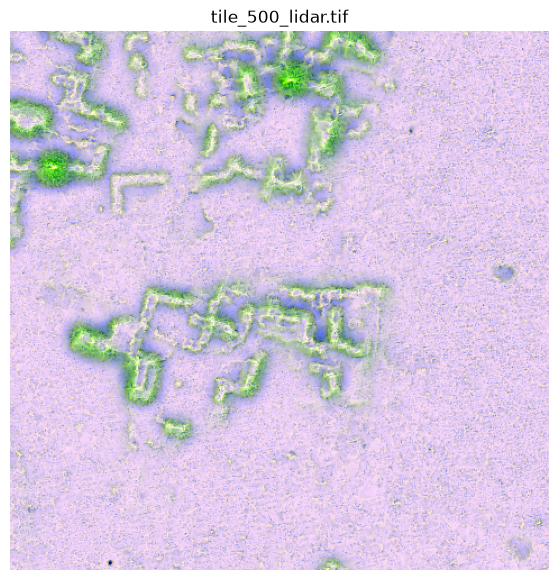

In [65]:
sample_path = lidar_files[500]

with rasterio.open(sample_path) as src:
    img = src.read()


img = np.transpose(img, (1, 2, 0))

plt.figure(figsize=(7, 7))
plt.imshow(img)
plt.title(sample_path.name)
plt.axis("off")
plt.show()

In [66]:
band_names = [
    "SVF",
    "Openness",
    "Slope"
]

for i, name in enumerate(band_names):

    band = image[i]

    print(
        f"{name}: "
        f"dtype={band.dtype}, "
        f"min={band.min()}, "
        f"max={band.max()}, "
        f"mean={band.mean():.2f}, "
        f"std={band.std():.2f}"
    )

SVF: dtype=uint8, min=0, max=255, mean=204.37, std=33.08
Openness: dtype=uint8, min=0, max=255, mean=195.18, std=18.60
Slope: dtype=uint8, min=0, max=255, mean=216.59, std=31.31


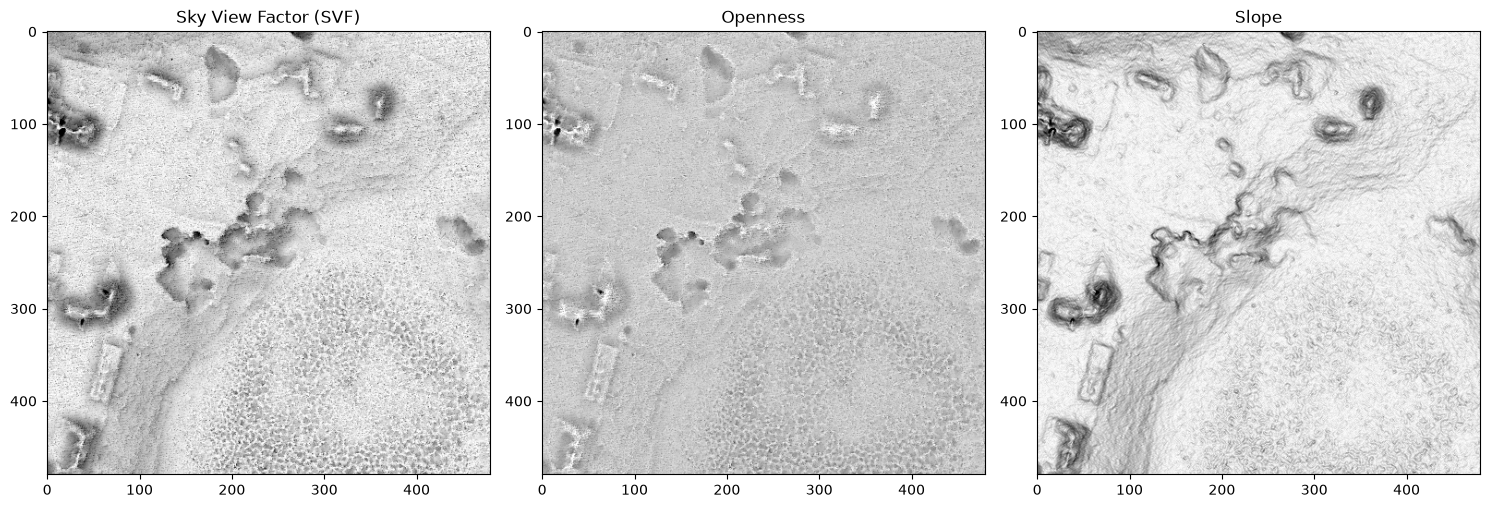

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [67]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(svf, cmap='gray')
axes[0].set_title("Sky View Factor (SVF)")
axes[1].imshow(openness, cmap='gray')
axes[1].set_title("Openness")
axes[2].imshow(slope, cmap='gray')
axes[2].set_title("Slope")
for ax in axes:
    plt.tight_layout()
    plt.show()

## Process Masks

In [68]:
def load_mask(mask_path):
    if mask_path is None:
        return None

    with rasterio.open(mask_path) as src:
        mask = src.read(1)

    return mask

In [69]:
building_mask = load_mask(Path(sample_row["building_mask"]))
platform_mask = load_mask(Path(sample_row["platform_mask"]))
aguada_mask = load_mask(Path(sample_row["aguada_mask"]))
print('Building', building_mask.shape, np.unique(building_mask))
print('Platform', platform_mask.shape, np.unique(platform_mask))
print('Aguada', aguada_mask.shape, np.unique(aguada_mask))


Building (480, 480) [  0 255]
Platform (480, 480) [  0 255]
Aguada (480, 480) [  0 255]


In [70]:
building_binary = (building_mask == 0).astype(np.uint8)
platform_binary = (platform_mask == 0).astype(np.uint8)
aguada_binary = (aguada_mask == 0).astype(np.uint8)
print(np.unique(building_binary))

[0 1]


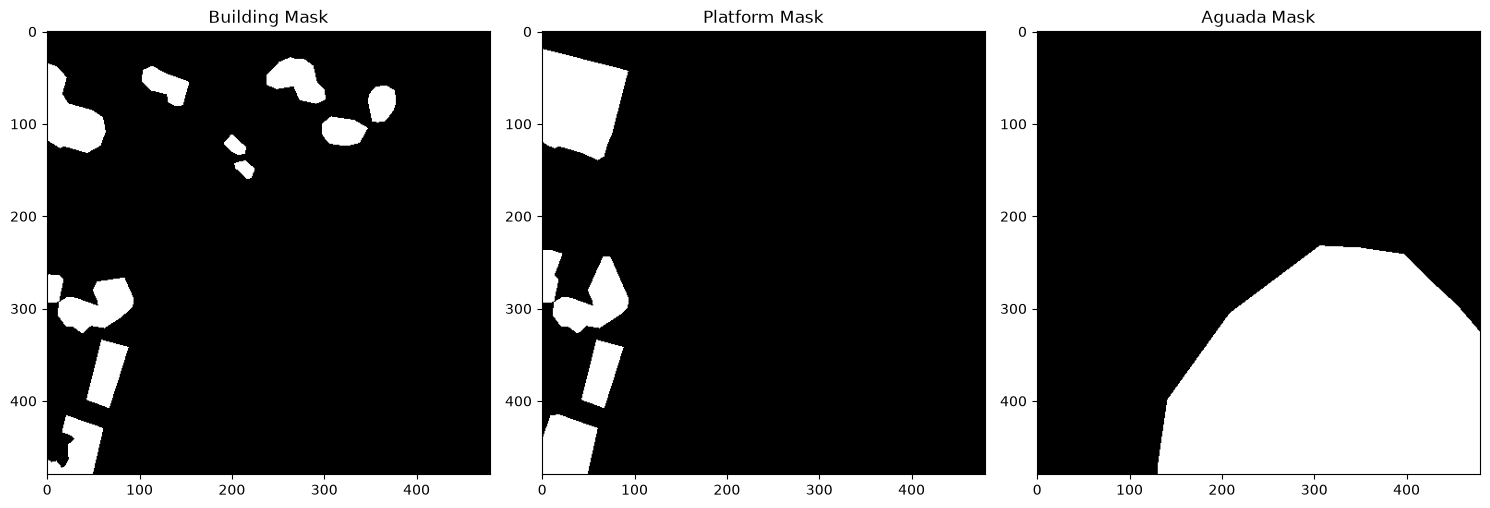

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [71]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(building_binary, cmap='gray')
axes[0].set_title("Building Mask")
axes[1].imshow(platform_binary, cmap='gray')
axes[1].set_title("Platform Mask")
axes[2].imshow(aguada_binary, cmap='gray')
axes[2].set_title("Aguada Mask")
for ax in axes:
    plt.tight_layout()
    plt.show()

## Validate Alignment 

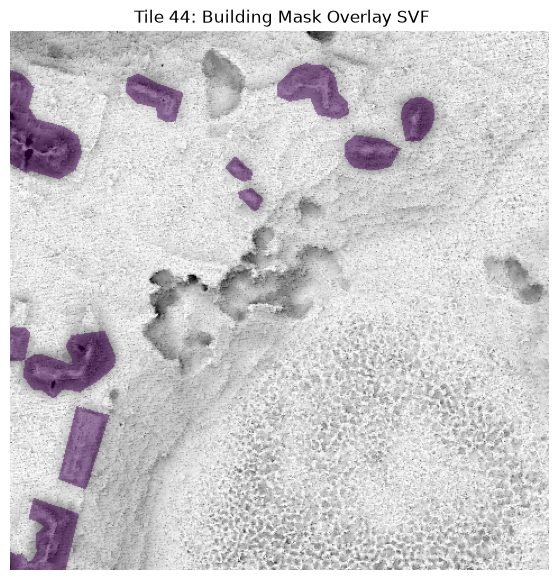

In [72]:
building_display = np.ma.masked_where(building_binary == 0, building_binary)
plt.figure(figsize=(7,7))
plt.imshow(svf, cmap='gray')
plt.imshow(building_display, alpha=0.5)
plt.title(f" Tile {sample_tile}: Building Mask Overlay SVF")
plt.axis('off')
plt.show()

In [73]:
building_path = Path(sample_row["building_mask"])
with rasterio.open(sample_lidar_path) as lidar_src, rasterio.open(building_path) as mask_src:
    print('Same shape:', lidar_src.shape == mask_src.shape)
    print('Same CRS:', lidar_src.crs == mask_src.crs)
    print('Same transform:', lidar_src.transform == mask_src.transform)
    print('Same bounds:', lidar_src.bounds == mask_src.bounds)
    
    

Same shape: True
Same CRS: True
Same transform: True
Same bounds: True


## Analyze mask overlap

In [74]:
building_platform_overlap = (building_binary.astype(bool) & platform_binary.astype(bool))
building_aquada_overlap = (building_binary.astype(bool) & aguada_binary.astype(bool))
platform_aquada_overlap = (platform_binary.astype(bool) & aguada_binary.astype(bool))
print("Building-Platform Overlap:", building_platform_overlap.sum())
print("Building-Aquada Overlap:", building_aquada_overlap.sum())
print("Platform-Aquada Overlap:", platform_aquada_overlap.sum())

Building-Platform Overlap: 11024
Building-Aquada Overlap: 0
Platform-Aquada Overlap: 0


In [75]:
total_bp_overlap = 0
total_ba_overlap = 0
total_pa_overlap = 0
for _, row in manifest.iterrows():
    building = (load_mask(Path(row["building_mask"])) == 0)
    platform = (load_mask(Path(row["platform_mask"])) == 0)
    aguada = (load_mask(Path(row["aguada_mask"])) == 0)
    total_bp_overlap += (building & platform).sum()
    total_ba_overlap += (building & aguada).sum()
    total_pa_overlap += (platform & aguada).sum()

print("Total Building-Platform Overlap:", total_bp_overlap)
print("Total Building-Aquada Overlap:", total_ba_overlap)
print("Total Platform-Aquada Overlap:", total_pa_overlap)

/home/jacobrawlins/Lidar_Project/.venv/lib/python3.12/site-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


Total Building-Platform Overlap: 4742911
Total Building-Aquada Overlap: 933
Total Platform-Aquada Overlap: 933


In [76]:

overlap_rows = []
for _, row in manifest.iterrows():
    building = (load_mask(Path(row["building_mask"])) == 0)
    platform = (load_mask(Path(row["platform_mask"])) == 0)
    aguada = (load_mask(Path(row["aguada_mask"])) == 0)
    bp = int((building & platform).sum())
    ba = int((building & aguada).sum())
    pa = int((platform & aguada).sum())
    if bp > 0 or ba > 0 or pa > 0:
        overlap_rows.append({
            "tile_id": row["tile_id"],
            "building_platform_overlap": bp,
            "building_aquada_overlap": ba,
            "platform_aquada_overlap": pa
        })
overlap_df = pd.DataFrame(overlap_rows)
overlap_df.head(25)


/home/jacobrawlins/Lidar_Project/.venv/lib/python3.12/site-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


,tile_id,building_platform_overlap,building_aquada_overlap,platform_aquada_overlap
0,1,6967,0,0
1,2,13793,0,0
2,5,1761,0,0
3,9,18593,0,0
4,12,4657,0,0
5,13,5991,0,0
6,14,6574,0,0
7,15,347,0,0
8,18,2304,0,0
9,19,1917,0,0


In [77]:
building_pixels = manifest["building_pixels"].sum()
platform_pixels = manifest["platform_pixels"].sum()
aguada_pixels = manifest["aguada_pixels"].sum()
pixels_per_tile = 480*480
total_pixels = len(manifest) * pixels_per_tile
print("Total pixels:", total_pixels)
print('Building', f'{building_pixels}', f'({100 * building_pixels / total_pixels:.4f}%)')
print('Platform', f'{platform_pixels}', f'({100 * platform_pixels / total_pixels:.4f}%)')
print('Aguada', f'{aguada_pixels}', f'({100 * aguada_pixels / total_pixels:.4f}%)')

Total pixels: 482457600
Building 8217562 (1.7033%)
Platform 10501412 (2.1766%)
Aguada 1594108 (0.3304%)


In [ ]:
total_building = 0
total_platform = 0
total_aguada = 0

bp_overlap = 0
ba_overlap = 0
pa_overlap = 0

for _, row in manifest.iterrows():

    building = (load_mask(Path(row["building_mask"])) == 0)
    platform = (load_mask(Path(row["platform_mask"])) == 0)
    aguada = (load_mask(Path(row["aguada_mask"])) == 0)

    total_building += building.sum()
    total_platform += platform.sum()
    total_aguada += aguada.sum()

    bp_overlap += (building & platform).sum()
    ba_overlap += (building & aguada).sum()
    pa_overlap += (platform & aguada).sum()


print("Total building pixels:", total_building)
print("Total platform pixels:", total_platform)
print("Total aguada pixels:", total_aguada)

print()

print("Building pixels overlapping platform:", bp_overlap / total_building * 100,"%")

print("Platform pixels overlapping building:", bp_overlap / total_platform * 100,"%")

print("Building pixels overlapping aguada:", ba_overlap / total_building * 100,"%")

print("Platform pixels overlapping aguada:", pa_overlap / total_platform * 100, "%")

/home/jacobrawlins/Lidar_Project/.venv/lib/python3.12/site-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


Total building pixels: 8217562
Total platform pixels: 10501412
Total aguada pixels: 1594108

Building pixels overlapping platform: 57.71676562951396 %
Platform pixels overlapping building: 45.16450740148087 %
Building pixels overlapping aguada: 0.011353732408711976 %
Platform pixels overlapping aguada: 0.008884519529373764 %


In [79]:
overlap_analysis = []

for _, row in manifest.iterrows():

    building = (
        load_mask(Path(row["building_mask"])) == 0
    )

    platform = (
        load_mask(Path(row["platform_mask"])) == 0
    )

    aguada = (
        load_mask(Path(row["aguada_mask"])) == 0
    )

    building_count = int(building.sum())
    platform_count = int(platform.sum())
    aguada_count = int(aguada.sum())

  
    intersection = int(np.logical_and(building, platform).sum())

    
    union = int(np.logical_or(building, platform).sum())

   
    iou = intersection / union if union > 0 else np.nan


    agreement = float(np.mean(building == platform))


    building_only_count = int(np.logical_and(building, ~platform).sum())

    platform_only_count = int(np.logical_and(platform, ~building).sum())

    overlap_analysis.append({
        "tile_id": row["tile_id"],
        "building_pixels": building_count,
        "platform_pixels": platform_count,
        "aguada_pixels": aguada_count,
        "bp_intersection": intersection,
        "bp_union": union,
        "bp_iou": iou,
        "bp_agreement": agreement,
        "building_only": building_only_count,
        "platform_only": platform_only_count
    })

overlap_analysis_df = pd.DataFrame(overlap_analysis)


feature_tiles = overlap_analysis_df[overlap_analysis_df["bp_union"] > 0].copy()

print("Tiles with building or platform pixels:", len(feature_tiles))

print("\nBuilding-platform IoU statistics:")
print(feature_tiles["bp_iou"].describe())

print("\nTiles with IoU >= 0.95:")
print((feature_tiles["bp_iou"] >= 0.95).sum())

print("\nTiles with IoU == 1.0:")
print((feature_tiles["bp_iou"] == 1.0).sum())

display(
    feature_tiles.sort_values(
        "bp_iou",
        ascending=False
    ).head(20)
)

/home/jacobrawlins/Lidar_Project/.venv/lib/python3.12/site-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


Tiles with building or platform pixels: 1407

Building-platform IoU statistics:
count    1407.000000
mean        0.248658
std         0.239720
min         0.000000
25%         0.000000
50%         0.223644
75%         0.414404
max         1.000000
Name: bp_iou, dtype: float64

Tiles with IoU >= 0.95:
20

Tiles with IoU == 1.0:
15


,tile_id,building_pixels,platform_pixels,aguada_pixels,bp_intersection,bp_union,bp_iou,bp_agreement,building_only,platform_only
917,917,136,136,0,136,136,1.000000,1.000000,0,0
1192,1192,1965,1965,0,1965,1965,1.000000,1.000000,0,0
681,681,1011,1011,1023,1011,1011,1.000000,1.000000,0,0
1108,1108,2667,2667,0,2667,2667,1.000000,1.000000,0,0
48,48,2301,2301,0,2301,2301,1.000000,1.000000,0,0
1634,1634,760,760,0,760,760,1.000000,1.000000,0,0
453,453,565,565,0,565,565,1.000000,1.000000,0,0
476,476,11,11,0,11,11,1.000000,1.000000,0,0
437,437,2469,2469,0,2469,2469,1.000000,1.000000,0,0
1673,1673,1073,1073,0,1073,1073,1.000000,1.000000,0,0


/home/jacobrawlins/Lidar_Project/.venv/lib/python3.12/site-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


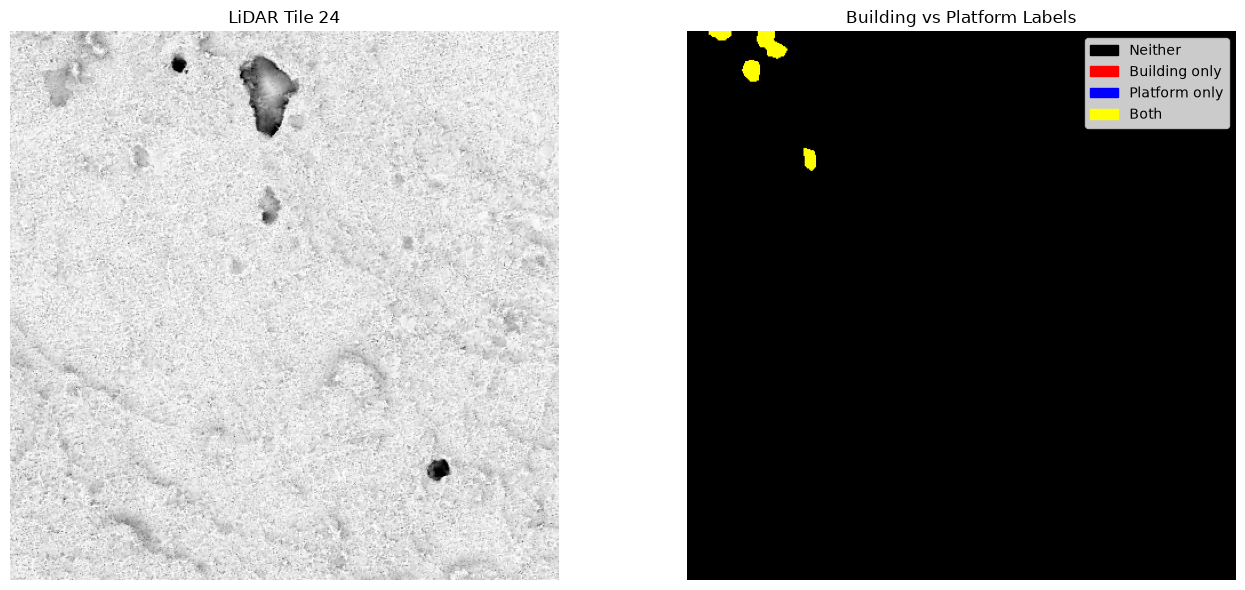

In [80]:

candidates = feature_tiles[
    (feature_tiles["building_pixels"] > 0) &
    (feature_tiles["platform_pixels"] > 0)
].sort_values("bp_iou", ascending=False)

if candidates.empty:
    raise ValueError(
        "No tiles contain both building and platform pixels."
    )

tile_id = int(candidates.iloc[0]["tile_id"])

row = manifest.loc[
    manifest["tile_id"] == tile_id
].iloc[0]

building = (
    load_mask(Path(row["building_mask"])) == 0
)

platform = (
    load_mask(Path(row["platform_mask"])) == 0
)

with rasterio.open(row["lidar_path"]) as src:
    image = src.read(1)

building_only = building & ~platform
platform_only = platform & ~building
both = building & platform


comparison = np.zeros(building.shape, dtype=np.uint8)

comparison[building_only] = 1
comparison[platform_only] = 2
comparison[both] = 3



colors = ListedColormap([
    "black",   
    "red",     
    "blue",    
    "yellow"   
])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(image, cmap="gray")
axes[0].set_title(f"LiDAR Tile {tile_id}")

axes[1].imshow(comparison, cmap=colors, vmin=0, vmax=3)
axes[1].set_title("Building vs Platform Labels")

legend = [
    Patch(color="black", label="Neither"),
    Patch(color="red", label="Building only"),
    Patch(color="blue", label="Platform only"),
    Patch(color="yellow", label="Both")
]

axes[1].legend(
    handles=legend,
    loc="upper right"
)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [81]:
building_only = 0
platform_only = 0
building_platform = 0
background = 0

for _, row in manifest.iterrows():

    building = (load_mask(Path(row["building_mask"])) == 0)
    platform = (load_mask(Path(row["platform_mask"])) == 0)
    aguada = (load_mask(Path(row["aguada_mask"])) == 0)

    building_only += (building & ~platform).sum()

    platform_only += (platform & ~building).sum()

    building_platform += (building & platform).sum()

    background += (~building & ~platform & ~aguada).sum()

print("Building only:", building_only)
print("Platform only:", platform_only)
print("Building + Platform:", building_platform)
print("Background:", background)

/home/jacobrawlins/Lidar_Project/.venv/lib/python3.12/site-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


Building only: 3474651
Platform only: 5758501
Building + Platform: 4742911
Background: 466888362


In [88]:
total_feature_pixels = 0
total_background_pixels = 0

for _, row in manifest.iterrows():

    building = (load_mask(Path(row["building_mask"])) == 0)

    platform = (load_mask(Path(row["platform_mask"])) == 0 )

    aguada = (load_mask(Path(row["aguada_mask"])) == 0)

  
    feature_pixels = building | platform | aguada

    background_pixels = ~feature_pixels

    total_feature_pixels += int(feature_pixels.sum())

    total_background_pixels += int(background_pixels.sum())

total_pixels = (total_feature_pixels + total_background_pixels)

print("Total feature pixels:", total_feature_pixels)
print("Total background pixels:", total_background_pixels)

print("Feature percentage:",100 * total_feature_pixels / total_pixels)

print("Background percentage:",100 * total_background_pixels / total_pixels)

/home/jacobrawlins/Lidar_Project/.venv/lib/python3.12/site-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


Total feature pixels: 15569238
Total background pixels: 466888362
Feature percentage: 3.2270686584686405
Background percentage: 96.77293134153136


In [83]:
shape_counts = {}
for path in lidar_files:
    with rasterio.open(path) as src:
        shape = ( src.count, src.height, src.width)
    shape_counts[shape] = shape_counts.get(shape, 0) + 1
print(shape_counts)

{(3, 480, 480): 2094}


In [84]:
dtype_counts = {}
for path in lidar_files:
    with rasterio.open(path) as src:
        dtype = src.dtypes
        dtype_counts[dtype] = dtype_counts.get(dtype, 0) + 1
print(dtype_counts)

{('uint8', 'uint8', 'uint8'): 2094}


In [85]:
resolutions = set()
for path in lidar_files:
    with rasterio.open(path) as src:
        resolutions.add(src.res)
print("Unique resolutions:", resolutions)

Unique resolutions: {(1.0, 1.0)}


In [86]:
crs_values = set()
for path in lidar_files:
    with rasterio.open(path) as src:
        crs_values.add(src.crs)
print("Number of unique CRS values:", len(crs_values))
print("Unique CRS values:", crs_values)

Number of unique CRS values: 1
Unique CRS values: {None}


In [87]:
processed_dir = Path("../data/processed/")
processed_dir.mkdir(parents=True, exist_ok=True)
manifest.to_csv(processed_dir / "manifest.csv", index=False)
manifest_path = processed_dir / "manifest.csv"
print("Manifest saved to:", manifest_path)
print("Manifest Exists:", manifest_path.exists())

Manifest saved to: ../data/processed/manifest.csv
Manifest Exists: True
